# COVID-19 Chest X-Ray (3-Class, real images)

Same caveat as the pneumonia notebook (104): **this is not a clinical model.** It's a small CNN on a small slice of real images, run on CPU.

Data: `hawking32/covid_chestXray` on Hugging Face (MIT tag on the card), a 6,432-image collection of real chest x-rays in three classes, `COVID19`, `NORMAL` and `PNEUMONIA`. It matches the widely used Kaggle "Chest X-ray (Covid-19 & Pneumonia)" collection, which pools public COVID x-rays (much of it from the Cohen et al. COVID-19 image data collection) with the normal and pneumonia x-rays from the Kermany pediatric dataset. The full set is about 2.3GB, so I read only a few parquet row groups (the files are sorted by class) and keep 300 images per class, resized to 64x64 grayscale. The full-resolution images are streamed and never stored.

The big caveat with this kind of pooled dataset is source leakage. The COVID images and the normal / pneumonia images mostly come from different hospitals, devices and patient ages (the Kermany images are children), so a model can score well by recognizing the source rather than the disease. I come back to this at the end.

In [1]:
import io
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, random_split
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
from huggingface_hub import HfFileSystem
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix

torch.set_num_threads(2)
torch.manual_seed(1); np.random.seed(1)
device = "cpu"
print("device:", device)

device: cpu


shape: (900, 64, 64)   counts: [300 300 300]


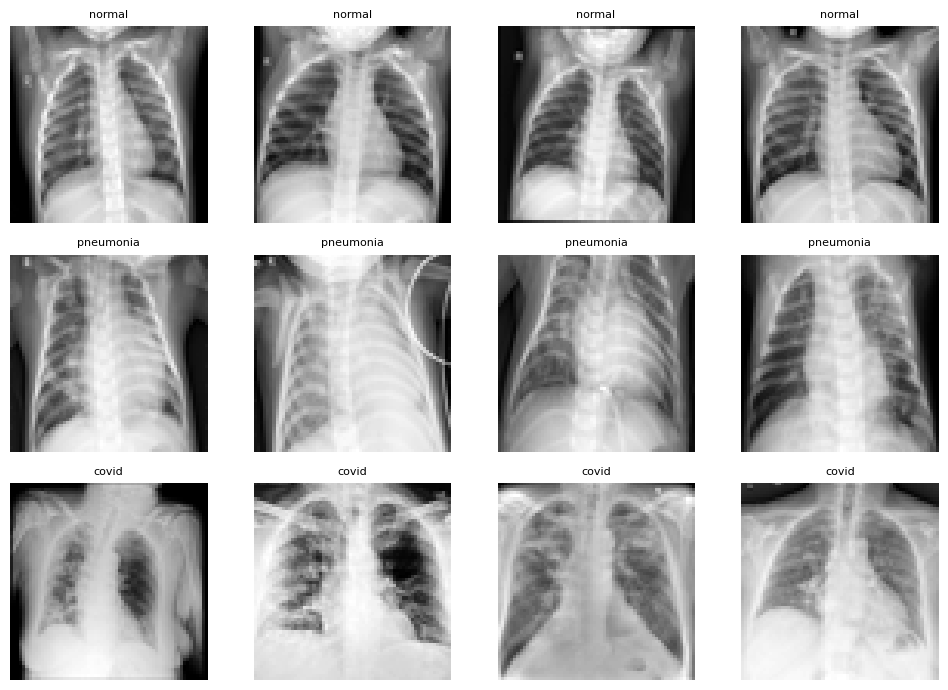

In [2]:
CACHE = Path("../../data/covid_xray/covid_xray_64.npz")
SRC_LABEL = {0: 2, 1: 0, 2: 1}   # dataset: 0 COVID19, 1 NORMAL, 2 PNEUMONIA -> mine: 0 normal, 1 pneumonia, 2 covid
PER_CLASS = 300
if not CACHE.exists():
    fs = HfFileSystem()
    root = "datasets/hawking32/covid_chestXray@refs%2Fconvert%2Fparquet/default/"
    files = [root + "train/0000.parquet", root + "test/0000.parquet"]
    imgs, labels = [], []
    taken = {0: 0, 1: 0, 2: 0}
    for f in files:
        pf = pq.ParquetFile(fs.open(f))
        for g in range(pf.metadata.num_row_groups):
            lab = pf.read_row_group(g, columns=["label"]).column("label").to_numpy()
            if all(taken[SRC_LABEL[l]] >= PER_CLASS for l in set(lab)):
                continue
            for row in pf.read_row_group(g).to_pylist():
                c = SRC_LABEL[row["label"]]
                if taken[c] < PER_CLASS:
                    im = Image.open(io.BytesIO(row["image"]["bytes"])).convert("L").resize((64, 64))
                    imgs.append(np.asarray(im, dtype=np.uint8)); labels.append(c); taken[c] += 1
        if all(v >= PER_CLASS for v in taken.values()):
            break
    CACHE.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(CACHE, imgs=np.stack(imgs), labels=np.array(labels))

d = np.load(CACHE)
imgs, labels = d["imgs"].astype(np.float32) / 255.0, d["labels"].astype(np.int64)
order = np.random.RandomState(1).permutation(len(labels))
imgs, labels = imgs[order], labels[order]
print("shape:", imgs.shape, "  counts:", np.bincount(labels))

class_names = ["normal", "pneumonia", "covid"]
fig, axes = plt.subplots(3, 4, figsize=(10, 7))
for c in range(3):
    idxs = np.where(labels == c)[0][:4]
    for j, i in enumerate(idxs):
        axes[c, j].imshow(imgs[i], cmap="gray"); axes[c, j].set_title(class_names[c], fontsize=8); axes[c, j].axis("off")
plt.tight_layout(); plt.show()

## Tiny 3-class CNN, weighted loss

The classes are balanced in my sample, so the inverse-frequency weights come out equal here. I left the weighting in because the real collection is imbalanced (COVID is the smallest class) and the code should handle that.

In [3]:
class XrayNet(nn.Module):
    def __init__(self, num_classes=3):
        super().__init__()
        self.feat = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(1),
        )
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(64, num_classes))
    def forward(self, x): return self.head(self.feat(x))

x = torch.tensor(imgs).unsqueeze(1); y = torch.tensor(labels, dtype=torch.long)
ds = TensorDataset(x, y)
n_tr = int(0.75 * len(ds))
tr_ds, te_ds = random_split(ds, [n_tr, len(ds) - n_tr], generator=torch.Generator().manual_seed(1))
tr_dl = DataLoader(tr_ds, batch_size=16, shuffle=True)
te_dl = DataLoader(te_ds, batch_size=32)

# inverse-frequency weights (all equal on my balanced sample)
counts = np.bincount(labels)
weights = torch.tensor((counts.sum() / counts), dtype=torch.float32, device=device)
print("class weights:", weights.tolist())

model = XrayNet().to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss(weight=weights)

for ep in range(8):
    model.train(); total, n = 0, 0
    for xb, yb in tr_dl:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad(); out = model(xb)
        l = loss_fn(out, yb); l.backward(); opt.step()
        total += l.item() * xb.size(0); n += xb.size(0)
    print(f"ep {ep+1}  train_loss={total/n:.3f}")

class weights: [3.0, 3.0, 3.0]


ep 1  train_loss=1.099


ep 2  train_loss=1.088


ep 3  train_loss=1.065


ep 4  train_loss=1.018


ep 5  train_loss=0.949


ep 6  train_loss=0.841


ep 7  train_loss=0.742


ep 8  train_loss=0.699


In [4]:
model.eval()
ys, ps = [], []
with torch.no_grad():
    for xb, yb in te_dl:
        xb = xb.to(device)
        ps.extend(model(xb).argmax(1).cpu().tolist())
        ys.extend(yb.tolist())

print(classification_report(ys, ps, target_names=class_names, digits=3))
print("confusion (rows=true, cols=pred):")
print(confusion_matrix(ys, ps))

              precision    recall  f1-score   support

      normal      0.562     0.973     0.713        74
   pneumonia      0.721     0.413     0.525        75
       covid      0.981     0.697     0.815        76

    accuracy                          0.693       225
   macro avg      0.755     0.695     0.685       225
weighted avg      0.757     0.693     0.685       225

confusion (rows=true, cols=pred):
[[72  2  0]
 [43 31  1]
 [13 10 53]]


## Results, and the leakage problem

On 225 held-out images (a random 25% of my 900-image sample), the CNN gets 69.3% accuracy after 8 epochs. The training loss was still dropping (0.70 at the end), so it's undertrained. The per-class pattern is the interesting part:

- When it says "covid" it's almost always right (precision 0.98), and it recovers 70% of the covid images.
- Pneumonia is the weak class: 43 of 75 pneumonia x-rays get called normal.

Covid being the *easiest* class should make anyone suspicious. You can see why in the sample grid above: the covid images are adult x-rays with different framing and contrast, while the normal and pneumonia images are small children from a single pediatric center. Telling those groups apart doesn't require seeing any disease at all, so I can't tell how much of the covid score is real signal and how much is source detection. My sampling makes it worse, because the covid images came from the dataset's train file and the pneumonia images from its test file.

What's actually transferable: the multi-class head, the inverse-frequency loss weighting (needed on the full, imbalanced collection), and the per-class confusion-matrix readout. That's the part I'd keep.

A real version would use a pretrained chest x-ray backbone (TorchXRayVision is a good starting point), a dataset where every class comes from the same hospitals (BIMCV-COVID19+ with its negative controls, for example), evaluation on at least one external hospital, and saliency checks to see whether the model looks at the lungs or at the borders and labels.